# Podstawy U-Net w PyTorch

Łączymy elementy U-Neta z kodem: od pojedynczych warstw i kształtów tensorów do uczenia małego modelu na jednej paczce MRI.
Notebook działa samodzielnie z kernelem **Python (inzynierka)**, z katalogu projektu lub `notebooks/`.

Najpierw korzystamy z danych syntetycznych, a potem z czterech przekrojów jednego pacjenta z części treningowej.
To próba dopasowania jednej paczki, a nie ocena generalizacji. Zapisany podział pacjentów pozostaje bez zmian; kandydaci `anomaly_candidate` nie są filtrowani.

Uruchamiaj komórki od góry. **Nie ustawiamy tu jeszcze ziarna losowania**, więc wagi, straty i Dice mogą różnić się między przebiegami.
Powtarzalny eksperyment na pełnym treningu i walidacji przygotujemy w notebooku 05.
Ćwiczenia oznaczone **DO ROZWAŻENIA USUNIĘCIA** zachowano w osobnej sekcji końcowej.

## 1. Biblioteki

`torch` i `nn` obsługują tensory oraz sieć. Pozostałe importy służą do ścieżek, tabel, odczytu TIFF-ów, wykresów oraz tworzenia `Dataset` i `DataLoader`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader


## 2. Splot, ReLU i pooling na sztucznej paczce

Tworzymy cztery losowe obrazy o takim samym układzie wymiarów jak nasze MRI: `(B, C, H, W) = (4, 3, 256, 256)`.
`torch.rand` losuje wartości z `[0, 1)`; te dane nie przedstawiają rzeczywistych przekrojów.

In [2]:
batch_images = torch.rand(4, 3, 256, 256)
batch_images.shape


torch.Size([4, 3, 256, 256])

Splot `3 × 3` z `padding=1` i `stride=1` zachowuje wysokość oraz szerokość. Liczba filtrów określa liczbę kanałów wyjściowych.
ReLU zeruje wartości ujemne, a pooling `2 × 2` z krokiem 2 zmniejsza rozdzielczość dwukrotnie, zachowując liczbę kanałów.

In [3]:
conv = nn.Conv2d(3, 8, kernel_size=3, padding=1, stride=1)
conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1, stride=1)
relu = nn.ReLU()
pool = nn.MaxPool2d(kernel_size=2, stride=2)

features = conv(batch_images)
print("conv1: ", features.shape)

activated_features = relu(features)
print("relu1: ", activated_features.shape)

pooled_features = pool(activated_features)
print("pool1: ", pooled_features.shape)

features2 = conv2(pooled_features)
print("conv2: ", features2.shape)

activated_features2 = relu(features2)
print("relu2: ", activated_features2.shape)


conv1:  torch.Size([4, 8, 256, 256])
relu1:  torch.Size([4, 8, 256, 256])
pool1:  torch.Size([4, 8, 128, 128])
conv2:  torch.Size([4, 16, 128, 128])
relu2:  torch.Size([4, 16, 128, 128])


## 3. Blok DoubleConv

`nn.Sequential` wykonuje warstwy po kolei. Zapisujemy dwa sploty z ReLU jako klasę dziedziczącą po `nn.Module`:
`__init__` tworzy warstwy, a `forward` opisuje przepływ danych.
`DoubleConv(3, 8)` zwraca osiem map cech w rozdzielczości wejścia; każda instancja ma własne uczone wagi.

In [4]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, stride=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, stride=1),
            nn.ReLU()
        )
    def forward(self, x):
        return self.layers(x)

block = DoubleConv(3, 8)
block_features = block(batch_images)

block_features.shape


torch.Size([4, 8, 256, 256])

## 4. Niższy poziom reprezentacji

Pooling zmienia rozmiar z `256 × 256` na `128 × 128`. Kolejny `DoubleConv` zwiększa liczbę kanałów z 8 do 16.
Ten fragment odpowiada zejściu na niższy poziom U-Neta.

In [5]:
deeper_block = DoubleConv(8, 16)
deeper_features = deeper_block(pool(block_features))

deeper_features.shape


torch.Size([4, 16, 128, 128])

## 5. Zwiększenie rozdzielczości

`ConvTranspose2d(16, 8, kernel_size=2, stride=2)` jest uczoną operacją zwiększającą rozdzielczość do `256 × 256`.
Jej wynik i zachowane cechy z wyższego poziomu mają zgodne wymiary przestrzenne, potrzebne do skip connection.

In [6]:
upconv = nn.ConvTranspose2d(16, 8, kernel_size=2, stride=2)
upsampled_features = upconv(deeper_features)

upsampled_features.shape, block_features.shape


(torch.Size([4, 8, 256, 256]), torch.Size([4, 8, 256, 256]))

## 6. Skip connection i decoder

`torch.cat(..., dim=1)` dokłada kanały: `8 + 8 = 16`. Wymiary paczki, wysokości i szerokości muszą się zgadzać.
Następny `DoubleConv(16, 8)` uczy się łączyć informacje z encodera i decodera.

In [7]:
combined_features = torch.cat(
    (block_features, upsampled_features),
    dim=1
)

print("Po konkatenacji:", combined_features.shape)

decoder_block = DoubleConv(16, 8)
decoder_features = decoder_block(combined_features)

print("Po decoderze:", decoder_features.shape)


Po konkatenacji: torch.Size([4, 16, 256, 256])
Po decoderze: torch.Size([4, 8, 256, 256])


## 7. Splot 1 × 1 i logity

Końcowy splot łączy osiem cech w każdej pozycji w jedną wartość. `1 × 1` określa rozmiar przestrzenny filtra; liczba filtrów określa kanały wyjściowe.
Otrzymujemy `(4, 1, 256, 256)` surowych logitów, które mogą mieć dowolny znak.

In [8]:
head = nn.Conv2d(8, 1, kernel_size=1)
logits = head(decoder_features)

print(logits.shape)
print(logits.min().item(), logits.max().item())


torch.Size([4, 1, 256, 256])
0.001315496047027409 0.024198701605200768


## 8. Złożenie małego U-Neta

Łączymy poznane operacje w `MiniUNet`: jeden pooling, bottleneck, jedno zwiększenie rozdzielczości i jeden skip connection.
Wynik encodera zachowujemy przed poolingiem. `forward` zwraca logity o tym samym rozmiarze przestrzennym co maski.
Definicje pozostają tutaj jako materiał do nauki; do kolejnych eksperymentów zostały również wydzielone do `src/models.py`.

In [9]:
class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = DoubleConv(3, 8)
        self.pool = nn.MaxPool2d(2, stride=2)
        self.bottleneck = DoubleConv(8, 16)
        self.upconv = nn.ConvTranspose2d(16, 8, kernel_size=2, stride=2)
        self.decoder = DoubleConv(16, 8)
        self.head = nn.Conv2d(8, 1, kernel_size=1)

    def forward(self, x):
        skip_connection1 = self.encoder(x)
        bottleneck = self.bottleneck(self.pool(skip_connection1))
        upsampled = self.upconv(bottleneck)

        combined = torch.cat((upsampled, skip_connection1), dim=1)
        logits = self.head(self.decoder(combined))

        return logits


Sprawdzamy cały model na sztucznej paczce i tworzymy puste maski wzorcowe.
`BCEWithLogitsLoss` przyjmuje logity oraz maski `0/1` typu zmiennoprzecinkowego; zawiera obliczenia odpowiadające sigmoidowi w stabilnej postaci.
Domyślnie zwraca średnią stratę jako tensor skalarny, dlatego `loss.shape` ma postać `torch.Size([])`.

In [10]:
model = MiniUNet()
logits = model(batch_images)
print(logits.shape)

batch_masks = torch.zeros_like(logits)
criterion = nn.BCEWithLogitsLoss()
loss = criterion(logits, batch_masks)

print(loss.shape)
print(loss.item())


torch.Size([4, 1, 256, 256])
torch.Size([])
0.6559622883796692


## 9. Jeden krok uczenia na danych syntetycznych

Adam otrzymuje parametry modelu i współczynnik uczenia `lr=1e-3`. Tworzymy go przed krokiem uczenia, aby mógł zachować historię aktualizacji.

In [11]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


Kolejność to: wyczyszczenie gradientów, przejście w przód, strata, `backward()` i `step()`.
`backward()` oblicza gradienty, a dopiero `step()` aktualizuje wagi. Ponowna ocena tej samej paczki w `no_grad()` pozwala porównać stratę przed i po aktualizacji.

In [12]:
optimizer.zero_grad(set_to_none=True)

logits = model(batch_images)
loss = criterion(logits, batch_masks)
loss_before = loss.item()

loss.backward()
optimizer.step()

with torch.no_grad():
    loss_after = criterion(model(batch_images), batch_masks).item()

print(loss_before, loss_after)


0.6559622883796692 0.6520605683326721


## 10. Od logitów do maski

Sigmoid przelicza logity na prawdopodobieństwa. Próg `0.5` tworzy maskę logiczną o tym samym kształcie.
Progowanie służy interpretacji wyniku; funkcja straty podczas uczenia otrzymuje surowe logity.

In [13]:
with torch.no_grad():
    logits = model(batch_images)
    probabilities = torch.sigmoid(logits)
    predicted_masks = probabilities >= 0.5

print(probabilities.min().item(), probabilities.max().item())
print(predicted_masks.shape, predicted_masks.dtype)


0.4753321707248688 0.4812004566192627
torch.Size([4, 1, 256, 256]) torch.bool


## 11. Wybór rzeczywistych przykładów treningowych

Ustalamy katalog projektu i odczytujemy metadane oraz zapisany przydział pacjentów.
`merge(..., validate="many_to_one")` sprawdza, czy każdemu pacjentowi odpowiada najwyżej jeden wiersz przydziału. Wybieramy wyłącznie `train`.

In [14]:
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

metadata_dir = project_root / "data" / "metadata"
split_dir = project_root / "data" / "splits"

pairs_df = pd.read_csv(metadata_dir / "pairs.csv")
splits_df = pd.read_csv(split_dir / "splits.csv")

pairs_with_split = pairs_df.merge(
    splits_df,
    on="patient_id",
    how="left",
    validate="many_to_one",
)

train_df = pairs_with_split[pairs_with_split["split"] == "train"]


Do diagnostycznej paczki wybieramy dwa pierwsze przekroje z oznaczeniem i dwa pierwsze z pustą maską.
W aktualnych metadanych są to przekroje `11, 12, 1, 2` pacjenta `TCGA_CS_4941_19960909`.
Flaga `anomaly_candidate` pozostaje informacją z audytu; ta komórka nie wyklucza kandydatów.

In [15]:
example_df = pd.concat(
    [
        train_df[train_df["has_annotation"]].head(2),
        train_df[~train_df["has_annotation"]].head(2),
    ],
    ignore_index=True,
)

example_df


,patient_id,image_path,mask_path,slice_id,foreground_pixels,has_annotation,anomaly_candidate,split
0,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,11,1426,True,False,train
1,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,12,2646,True,False,train
2,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,1,0,False,True,train
3,TCGA_CS_4941_19960909,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,data/raw/TCGA_CS_4941_19960909/TCGA_CS_4941_19...,2,0,False,False,train


## 12. Preprocessing i odczyt paczki MRI

Wykorzystujemy rozwiązanie z notebooka 03. Obraz zmienia układ z `(H, W, C)` na `(C, H, W)` i jest dzielony przez 255.
Maska otrzymuje wartości `0/1` i dodatkową oś kanału. `MRIDataset` odczytuje pliki na żądanie, wybierając wiersz przez `iloc`.

In [16]:
def preprocess_pair(image, mask):
    image_tensor = torch.from_numpy(image).permute(2, 0, 1).float() / 255
    mask_tensor = torch.from_numpy(mask > 0).float().unsqueeze(0)

    return (image_tensor, mask_tensor)

class MRIDataset(Dataset):
    def __init__(self, pairs_df, project_root):
        self.pairs_df = pairs_df
        self.project_root = project_root

    def __len__(self):
        return self.pairs_df.shape[0]

    def __getitem__(self, index):
        row = self.pairs_df.iloc[index]
        image_path = self.project_root / row["image_path"]
        mask_path = self.project_root / row["mask_path"]
        return preprocess_pair(tifffile.imread(image_path), tifffile.imread(mask_path))


Loader zachowuje kolejność czterech przykładów (`shuffle=False`). Osobne nazwy `real_images` i `real_masks` odróżniają MRI od danych syntetycznych.
Kontrolujemy kształty, typy i wartości masek. Sumowanie po osiach `(1, 2, 3)` pozostawia osobny wynik dla każdej próbki:
`[1426, 2646, 0, 0]` pikseli oznaczenia.

In [17]:
example_dataset = MRIDataset(example_df, project_root)

example_loader = DataLoader(
    example_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

real_images, real_masks = next(iter(example_loader))

print(real_images.shape, real_images.dtype)
print(real_masks.shape, real_masks.dtype)
print(torch.unique(real_masks))
print(real_masks.sum(dim=(1, 2, 3)))


torch.Size([4, 3, 256, 256]) torch.float32
torch.Size([4, 1, 256, 256]) torch.float32
tensor([0., 1.])
tensor([1426., 2646.,    0.,    0.])


## 13. Predykcja przed uczeniem na MRI

Tworzymy świeży model. `eval()` ustawia tryb ewaluacji warstw, a `no_grad()` wyłącza rejestrowanie grafu do obliczania gradientów.
W tym modelu nie ma Dropoutu ani BatchNorm, więc samo `eval()` nie zmienia wartości obliczeń.
Wyniki zachowujemy z przyrostkiem `_before`, aby późniejsze etapy ich nie nadpisały.

In [18]:
real_model = MiniUNet()
real_model.eval()

with torch.no_grad():
    real_logits_before = real_model(real_images)
    real_probabilities_before = torch.sigmoid(real_logits_before)
    real_predictions_before = real_probabilities_before >= 0.5


Cztery panele pokazują FLAIR (kanał 1), maskę wzorcową, prawdopodobieństwa i maskę po progowaniu.
Oba dolne panele dotyczą tego samego etapu; stała skala `[0, 1]` umożliwia porównanie jasności między etapami.

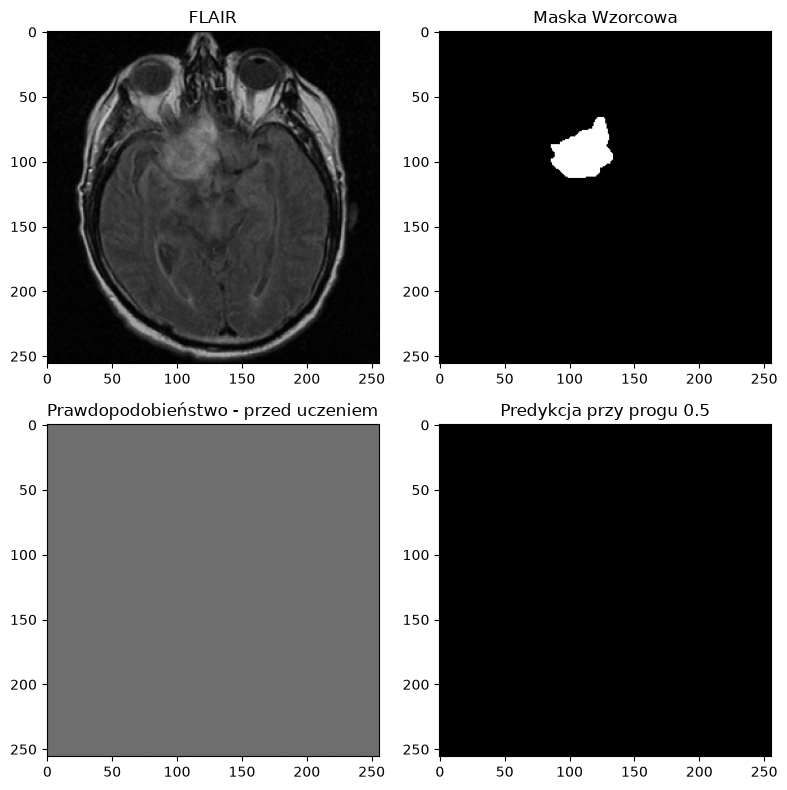

In [19]:
i = 0 
fig, ax = plt.subplots(2, 2, figsize=(8, 8))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FLAIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities_before[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - przed uczeniem")

ax[1, 1].imshow(real_predictions_before[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Predykcja przy progu 0.5")

plt.tight_layout()
plt.show()


## 14. Urządzenie i optymalizator dla MRI

Model i wejścia przenosimy na to samo urządzenie: CUDA, jeśli jest dostępna, albo CPU.
`real_images` i `real_masks` pozostają na CPU do wykresów. Nowy Adam jest powiązany z `real_model`, a nie z modelem używanym wcześniej na sztucznych danych.

In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

real_model = real_model.to(device)
training_images = real_images.to(device)
training_masks = real_masks.to(device)

real_optimizer = torch.optim.Adam(real_model.parameters(), lr=1e-3)

print(device)


cuda


## 15. Pierwsze 100 aktualizacji tej samej paczki

W każdej iteracji używamy tych samych czterech przekrojów. To kroki optymalizacji jednej paczki, a nie epoki pełnego zbioru.
Strata jest wypisywana co 20 kroków, przed aktualizacją wag w danej iteracji. Na tym etapie nie korzystamy z walidacji ani testu.

In [21]:
real_model.train()

for step in range(100):
    real_optimizer.zero_grad(set_to_none=True)
    logits = real_model(training_images)
    loss = criterion(logits, training_masks)
    loss.backward()
    real_optimizer.step()

    if (step + 1) % 20 == 0:
        print(step + 1, loss.item())


20 0.3874635100364685
40 0.13760226964950562
60 0.08855659514665604
80 0.0618911050260067
100 0.04381083697080612


Ponownie obliczamy predykcje aktualnego modelu i zapisujemy je osobno jako wyniki `_100`.
`.cpu()` pozwala rysować je przez Matplotlib i porównywać z maskami na CPU.
Zliczamy oznaczenie, predykcję i ich część wspólną; `&` działa logicznie dla odpowiadających sobie pikseli.

In [22]:
real_model.eval()

with torch.no_grad():
    real_logits_100 = real_model(training_images)
    real_probabilities_100 = torch.sigmoid(real_logits_100).cpu()
    real_predictions_100 = real_probabilities_100 >= 0.5

print("Wzorzec:", real_masks.sum(dim=(1, 2, 3)))
print("Predykcja:", real_predictions_100.sum(dim=(1, 2, 3)))

intersection_100 = real_predictions_100 & (real_masks > 0)
print("Część wspólna:", intersection_100.sum(dim=(1, 2, 3)))


Wzorzec: tensor([1426., 2646.,    0.,    0.])
Predykcja: tensor([0, 0, 0, 0])
Część wspólna: tensor([0, 0, 0, 0])


Przekrój z oznaczeniem po 100 krokach. Mapa prawdopodobieństw może mieć widoczny jaśniejszy obszar, nawet jeśli wszystkie wartości pozostają poniżej progu i maska binarna jest pusta.

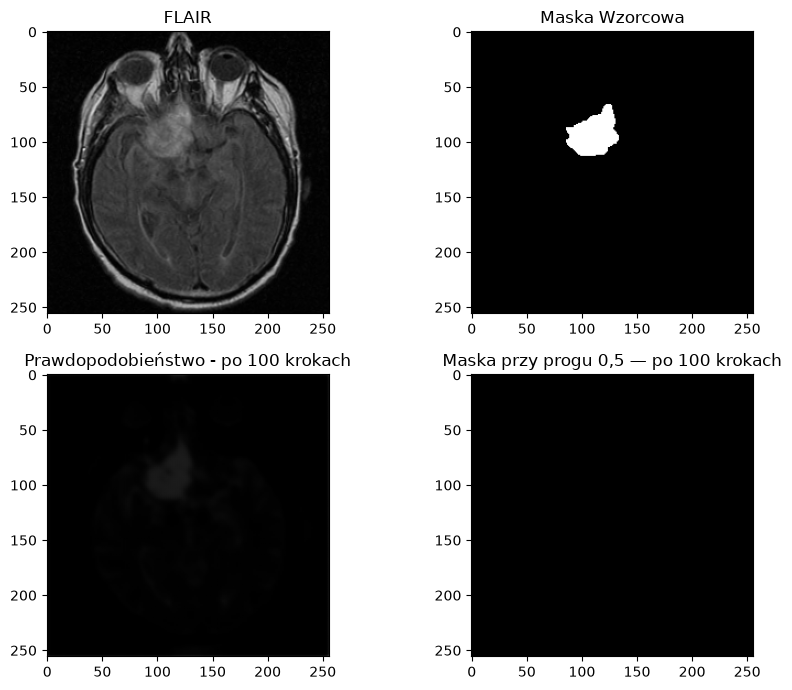

In [23]:
i = 0 
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FLAIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities_100[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - po 100 krokach")

ax[1, 1].imshow(real_predictions_100[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Maska przy progu 0,5 — po 100 krokach")

plt.tight_layout()
plt.show()


Przekrój z pustą maską po tych samych 100 krokach. Nietypowy ukośny czarny obszar FLAIR jest zapisany w źródłowym TIFF-ie.
Jego obecność była powodem rozszerzenia audytu w notebooku 01; sama nie dowodzi nieprzydatności pary.

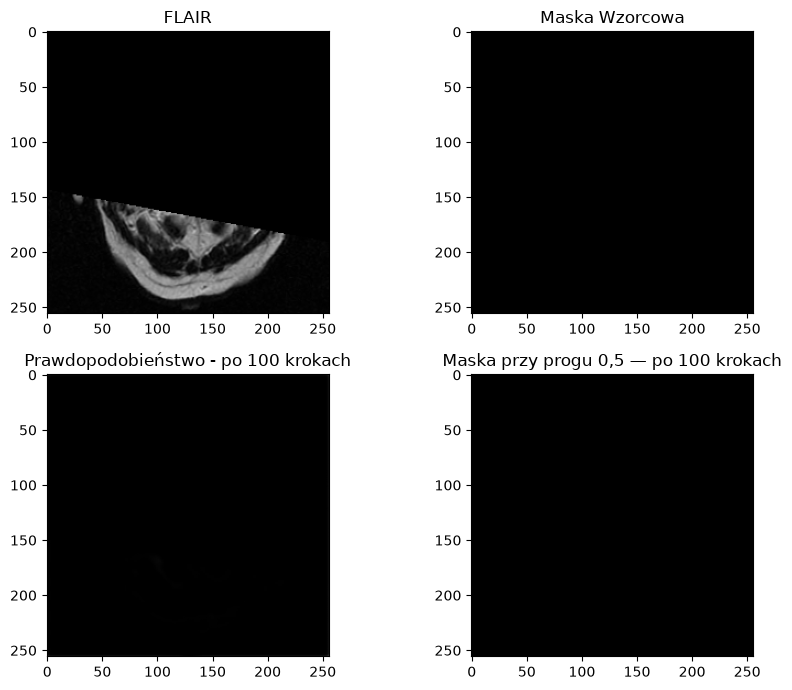

In [24]:
i = 2 
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FLAIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities_100[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo - po 100 krokach")

ax[1, 1].imshow(real_predictions_100[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Maska przy progu 0,5 — po 100 krokach")

plt.tight_layout()
plt.show()


## 16. Dalsze 400 aktualizacji — łącznie 500

Kontynuujemy uczenie tego samego modelu tym samym optymalizatorem. Zmieniamy wyłącznie liczbę kroków, zachowując paczkę, BCE i `lr`.
Numer w wydruku uwzględnia pierwsze 100 aktualizacji. Ponowne uruchomienie samej tej komórki doda kolejne 400 kroków, więc opis „500” dotyczy pojedynczego wykonania całego notebooka od początku.

In [25]:
real_model.train()

for step in range(400):
    real_optimizer.zero_grad(set_to_none=True)
    logits = real_model(training_images)
    loss = criterion(logits, training_masks)
    loss.backward()
    real_optimizer.step()

    if (step + 1) % 20 == 0:
        print(100 + step + 1, loss.item())


120 0.0330158993601799
140 0.027290431782603264
160 0.02451349049806595
180 0.0228485818952322
200 0.02164021134376526
220 0.020682955160737038
240 0.019894175231456757
260 0.01923821121454239
280 0.0186910443007946
300 0.018251951783895493
320 0.01790161058306694
340 0.017559390515089035
360 0.017228513956069946
380 0.01691918820142746
400 0.016626719385385513
420 0.016353918239474297
440 0.01609731651842594
460 0.015800464898347855
480 0.015513015910983086
500 0.014448869973421097


Oceniamy model po łącznie 500 aktualizacjach. Wyniki `_500` są oddzielone od predykcji sprzed treningu i po 100 krokach.
Zgodność liczby pikseli nie wystarcza do oceny położenia maski, dlatego zachowujemy również część wspólną.

In [26]:
real_model.eval()

with torch.no_grad():
    real_logits_500 = real_model(training_images)
    real_probabilities_500 = torch.sigmoid(real_logits_500).cpu()
    real_predictions_500 = real_probabilities_500 >= 0.5

print("Wzorzec:", real_masks.sum(dim=(1, 2, 3)))
print("Predykcja:", real_predictions_500.sum(dim=(1, 2, 3)))

intersection_500 = real_predictions_500 & (real_masks > 0)
print("Część wspólna:", intersection_500.sum(dim=(1, 2, 3)))


Wzorzec: tensor([1426., 2646.,    0.,    0.])
Predykcja: tensor([13, 75,  0,  0])
Część wspólna: tensor([12, 69,  0,  0])


Mapa prawdopodobieństw i jej progowanie po 500 krokach pokazują ten sam etap treningu.
Wszystkie wyniki tutaj dotyczą wyłącznie paczki użytej do aktualizacji wag.

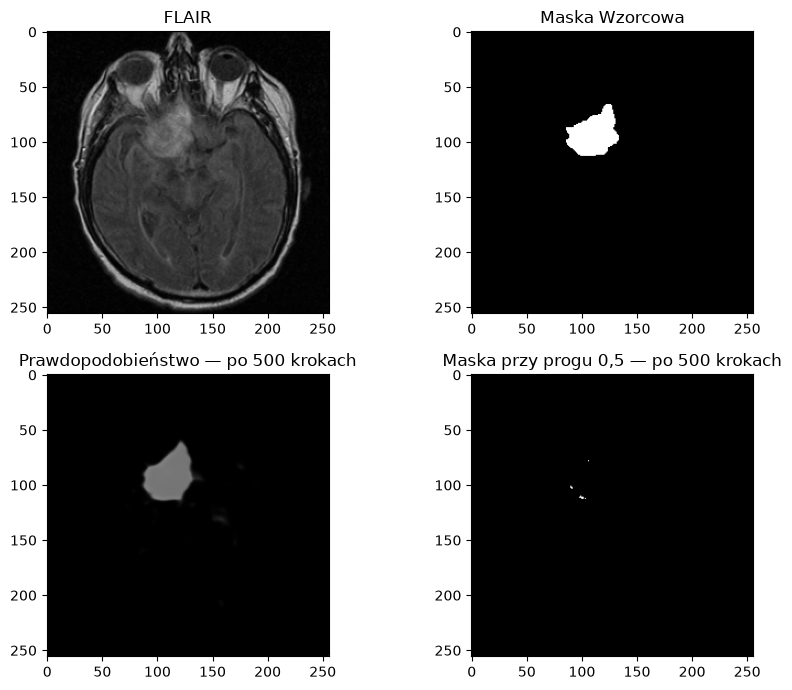

In [27]:
i = 0 
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
ax[0, 0].imshow(real_images[i, 1], cmap="grey", vmin=0, vmax=1)
ax[0, 0].set_title("FLAIR")

ax[0, 1].imshow(real_masks[i, 0], cmap="grey", vmin=0, vmax=1)
ax[0, 1].set_title("Maska Wzorcowa")

ax[1, 0].imshow(real_probabilities_500[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 0].set_title("Prawdopodobieństwo — po 500 krokach")

ax[1, 1].imshow(real_predictions_500[i, 0], cmap="grey", vmin=0, vmax=1)
ax[1, 1].set_title("Maska przy progu 0,5 — po 500 krokach")

plt.tight_layout()
plt.show()


## 17. Dice dla każdej próbki

Liczymy Dice na binarnych predykcjach: `2 * część_wspólna / (piksele_predykcji + piksele_wzorca)`.
Wynik 1 oznacza identyczne maski. Przyjmujemy jawnie: obie maski puste → 1; tylko jedna pusta → 0.
`clamp_min(1)` zabezpiecza dzielenie w `torch.where`. Ta metryka służy raportowaniu, a BCE pozostaje funkcją straty.

In [28]:
def dice_per_sample(predictions, targets):
    targets_logic = targets > 0

    targets_sum = targets_logic.sum(dim=(1, 2, 3))
    predictions_sum = predictions.sum(dim=(1, 2, 3))
    intersection = (targets_logic & predictions).sum(dim=(1, 2, 3))

    denominator = targets_sum + predictions_sum

    return torch.where(
        denominator == 0,
        1.0,
        2 * intersection / denominator.clamp_min(1)
    )


Podajemy wyniki pojedynczych przekrojów i średnie dla całej paczki, przekrojów z oznaczeniem oraz pustych masek.
Poprawnie przewidziane puste maski mogą podnosić średnią ogólną; pojedyncze fałszywe wskazanie przy pustym wzorcu daje w tej konwencji Dice 0.

In [29]:
has_annotation = real_masks.sum(dim=(1, 2, 3)) > 0

dice_scores = dice_per_sample(real_predictions_500, real_masks)
print(dice_scores)
print("Średnie:")
print("Cała paczka:", dice_scores.mean().item())
print("Z oznaczeniem:", dice_scores[has_annotation].mean().item())
print("Puste maski:", dice_scores[~has_annotation].mean().item())


tensor([0.0167, 0.0507, 1.0000, 1.0000])
Średnie:
Cała paczka: 0.5168486833572388
Z oznaczeniem: 0.033697448670864105
Puste maski: 1.0


Próba jednej paczki sprawdza, czy model i procedura uczenia potrafią dopasować kilka przykładów.
W jednym z wcześniejszych przebiegów uzyskaliśmy Dice około `0.9461` i `0.9567` na przekrojach z oznaczeniem oraz `1` na pustych maskach.
Bieżące zapisane wyniki po uporządkowaniu notebooka pochodzą z nowego wykonania całego kodu i mogą być znacznie słabsze: 500 aktualizacji przy losowej inicjalizacji nie gwarantuje takiego samego dopasowania.
To powód, by przed porównywaniem eksperymentów ustalić ziarno losowania i zapisywać ustawienia.
Ocenę na innych pacjentach oraz trening pełnego `train` i walidację przygotujemy w notebooku 05.

## 18. DO ROZWAŻENIA USUNIĘCIA — dodatkowe ćwiczenia

Poniższe komórki zachowują wcześniejsze próby i powtórzenia. Główna część notebooka nie korzysta z ich wyników, więc można usunąć tę sekcję bez naruszenia jej zależności.
Ćwiczenia wymagają wcześniejszego wykonania głównej części. Zmienne pomocnicze mają prefiks `extra_`, aby nie nadpisywać wyników eksperymentu MRI.
Przeniesienie dodatkowego losowo inicjalizowanego bloku na koniec zmienia kolejność losowań względem dawnego układu; bez ustalonego ziarna dokładne wyniki nie są stałe.

### A — DO ROZWAŻENIA USUNIĘCIA: osobny blok nn.Sequential i kontrola filtrów

To zapis dwóch splotów z ReLU poprzedzający klasę `DoubleConv`. Powtarza strukturę obecną w głównej części.
Wagi splotu mają układ `(filtry, kanały_wejściowe, wysokość_filtra, szerokość_filtra)`.

In [30]:
extra_block = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1, stride=1),
    nn.ReLU(),
    nn.Conv2d(8, 8, kernel_size=3, padding=1, stride=1),
    nn.ReLU()
)

extra_block_features = extra_block(batch_images)
print(extra_block_features.shape)

print(extra_block[0].weight.shape)
print(extra_block[2].weight.shape)


torch.Size([4, 8, 256, 256])
torch.Size([8, 3, 3, 3])
torch.Size([8, 8, 3, 3])


### B — DO ROZWAŻENIA USUNIĘCIA: osobna kontrola gradientów

Ponownie obliczamy gradienty modelu syntetycznego i sprawdzamy ich średnie wartości bezwzględne na początku oraz końcu sieci.
Pełny krok z `backward()` jest już w głównej części. To ćwiczenie nie wywołuje `step()` i nie aktualizuje wag.

In [31]:
model.zero_grad(set_to_none=True)

extra_logits = model(batch_images)
extra_loss = criterion(extra_logits, batch_masks)
extra_loss.backward()

print(model.head.weight.grad.abs().mean().item())
print(model.encoder.layers[0].weight.grad.abs().mean().item())


0.016043514013290405
0.0009838285623118281


### C — DO ROZWAŻENIA USUNIĘCIA: dodatkowa diagnostyka po 100 krokach

Porównujemy prawdopodobieństwa w oznaczeniu i poza nim, korzystając z zachowanego wyniku `_100`.
Ta kontrola wyjaśniała puste maski przy progu 0,5. Wykresy i późniejsze Dice pozostają w głównej części.

In [32]:
extra_foreground = real_masks > 0

print("Maksimum w całej paczce:",
      real_probabilities_100.max().item())

print("Średnia w oznaczeniu:",
      real_probabilities_100[extra_foreground].mean().item())

print("Średnia poza oznaczeniem:",
      real_probabilities_100[~extra_foreground].mean().item())

print("Maksimum w oznaczeniu:",
      real_probabilities_100[extra_foreground].max().item())


Maksimum w całej paczce: 0.21118739247322083
Średnia w oznaczeniu: 0.09233469516038895
Średnia poza oznaczeniem: 0.00549918320029974
Maksimum w oznaczeniu: 0.11472583562135696


### D — DO ROZWAŻENIA USUNIĘCIA: końcowa pusta komórka

Pozostawiona z pierwotnego notebooka. Nie zawiera kodu ani zależności.